# Customer Churn Prediction Using Machine Learning

## 1. Project Overview

Customer churn is an important business problem for companies that provide subscription-based products and services.

Customer churn occurs when a customer stops using a company's products or services. Being able to identify customers who are likely to churn can help businesses understand customer behavior and develop appropriate retention strategies.

In this project, we will develop a machine learning classification system that predicts whether a customer is likely to churn based on customer demographics, services, account information, contract details, and billing information.

We will use the IBM Telco Customer Churn dataset and follow a complete machine learning workflow, from data understanding and preprocessing to model training, evaluation, model persistence, and API deployment.

## 2. Problem Statement

The objective of this project is to build a machine learning model that predicts customer churn.

Given the available information about a customer, the model will predict whether the customer is likely to:

- **Churn (Yes)**
- **Not Churn (No)**

Since the target variable contains two possible classes, this problem is formulated as a **binary classification problem**.

## 3. Project Objectives

The main objectives of this project are:

1. Understand the structure and characteristics of the customer churn dataset.
2. Perform data quality checks and identify potential data issues.
3. Clean and prepare the dataset for machine learning.
4. Perform Exploratory Data Analysis (EDA).
5. Analyze relationships between customer characteristics and churn.
6. Perform appropriate feature engineering.
7. Handle missing values and categorical variables.
8. Analyze class distribution and potential class imbalance.
9. Split the dataset into training and testing sets.
10. Train multiple machine learning classification models.
11. Evaluate the models using appropriate performance metrics.
12. Compare model performance.
13. Select a final model based on the evaluation results.
14. Save the trained model for future predictions.
15. Develop a FastAPI REST API for making churn predictions.
16. Test the prediction API.
17. Document the project for GitHub and portfolio use.

## 4. Machine Learning Models

We will train and compare the following classification algorithms:

- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- Support Vector Machine (SVM)

The models will be evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC

## 7. Dataset Description

The IBM Telco Customer Churn dataset contains information about customers of a telecommunications company.

The dataset includes information related to:

- Customer demographics
- Customer tenure
- Services subscribed to
- Internet services
- Security and support services
- Contract type
- Payment method
- Paperless billing
- Monthly charges
- Total charges

The target variable is:

**Churn**

where:

- `Yes` indicates that the customer churned.
- `No` indicates that the customer did not churn.

The dataset contains approximately 7,043 customer records and 21 columns.

## 8. Skills and Machine Learning Concepts

This project will provide practical experience with:

- Python for Machine Learning
- Pandas and NumPy
- Data cleaning
- Data preprocessing
- Exploratory Data Analysis (EDA)
- Data visualization
- Feature engineering
- Categorical encoding
- Feature scaling
- Train/Test splitting
- Binary classification
- Supervised learning
- Class imbalance analysis
- Model training
- Cross-validation
- Hyperparameter tuning
- Model evaluation
- Confusion matrices
- Precision, Recall and F1-score
- ROC-AUC
- Model persistence
- REST API development
- Machine learning model deployment

## 9. Expected Outcome

By the end of this project, we aim to have:

1. A thoroughly analyzed customer churn dataset.
2. A cleaned and properly preprocessed dataset.
3. Meaningful Exploratory Data Analysis visualizations.
4. Multiple trained machine learning classification models.
5. A comparison of model performance using appropriate evaluation metrics.
6. A selected final model based on experimental results.
7. A saved trained machine learning model.
8. A FastAPI prediction service.
9. Tested API endpoints for customer churn prediction.
10. A professional GitHub repository with complete documentation.
11. A portfolio-ready project that demonstrates practical Machine Learning and AI Engineering skills.

In [12]:
# ============================================
# 10. Data Loading & Initial Investigation
# ============================================

# Import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Display all dataframe columns
pd.set_option("display.max_columns", None)

# Load dataset
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Basic overview
print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn Names:")
print(df.columns.tolist())

print("\n" + "=" * 70)
print("DATA TYPES AND NON-NULL COUNTS")
print("=" * 70)
df.info()

print("\n" + "=" * 70)
print("FIRST 5 RECORDS")
print("=" * 70)
display(df.head())

print("\n" + "=" * 70)
print("NUMERICAL SUMMARY")
print("=" * 70)
display(df.describe())

print("\n" + "=" * 70)
print("CATEGORICAL SUMMARY")
print("=" * 70)
display(df.describe(include="object"))

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

missing = df.isnull().sum()
missing = missing[missing > 0]

if len(missing) > 0:
    display(missing)
else:
    print("No standard missing values detected.")

Dataset loaded successfully!
Rows: 7043
Columns: 21

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



NUMERICAL SUMMARY


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



CATEGORICAL SUMMARY


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174



MISSING VALUES
No standard missing values detected.


In [13]:
# ============================================
# 11. Target Variable & Data Quality Overview
# ============================================

print("=" * 70)
print("TARGET VARIABLE: CHURN")
print("=" * 70)

print("\nChurn counts:")
display(df["Churn"].value_counts())

print("\nChurn percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

print("\n" + "=" * 70)
print("DUPLICATE ROWS")
print("=" * 70)

print("Number of duplicate rows:", df.duplicated().sum())

print("\n" + "=" * 70)
print("UNIQUE VALUES PER COLUMN")
print("=" * 70)

unique_counts = df.nunique().sort_values()
display(unique_counts)

print("\n" + "=" * 70)
print("TOTAL BLANK STRINGS")
print("=" * 70)

blank_counts = (df.astype(str).apply(lambda col: col.str.strip().eq("").sum()))
display(blank_counts[blank_counts > 0])

TARGET VARIABLE: CHURN

Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


DUPLICATE ROWS
Number of duplicate rows: 0

UNIQUE VALUES PER COLUMN


gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64


TOTAL BLANK STRINGS


TotalCharges    11
dtype: int64

## 11. Data Cleaning and Quality Checks

The initial dataset investigation identified an important data-quality issue in the `TotalCharges` column.

Although `TotalCharges` represents a numerical monetary value, it is stored as an `object` data type. The investigation also identified 11 blank values in this column.

We will convert `TotalCharges` to a numeric data type. Values that cannot be converted will become missing values (`NaN`), allowing us to handle them explicitly during preprocessing.

No duplicate rows were identified in the dataset.

In [15]:
# ============================================
# 11. Data Cleaning & Quality Checks
# ============================================

# Create a working copy so the original loaded dataset remains unchanged
df_clean = df.copy()

# Convert TotalCharges to numeric.
# Invalid/blank values are converted to NaN.
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check the result
print("TotalCharges data type:", df_clean["TotalCharges"].dtype)

print("\nMissing values after conversion:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nDuplicate rows:", df_clean.duplicated().sum())

TotalCharges data type: float64

Missing values after conversion:
TotalCharges    11
dtype: int64

Duplicate rows: 0


In [17]:
# Inspect records where TotalCharges is missing
missing_total_charges = df_clean[df_clean["TotalCharges"].isna()]

display(missing_total_charges)

print("Number of affected customers:", len(missing_total_charges))
print("\nTenure values:")
print(missing_total_charges["tenure"].value_counts())

print("\nChurn distribution among affected customers:")
print(missing_total_charges["Churn"].value_counts())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Number of affected customers: 11

Tenure values:
tenure
0    11
Name: count, dtype: int64

Churn distribution among affected customers:
Churn
No    11
Name: count, dtype: int64


In [18]:
# Target distribution
churn_distribution = df_clean["Churn"].value_counts(normalize=True) * 100

print("Churn Distribution:")
print(churn_distribution.round(2))

Churn Distribution:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## 11.1 Handling Missing `TotalCharges` Values

The investigation found 11 missing values in the `TotalCharges` column.

All 11 affected customers have a tenure of 0 months, indicating that they are new customers who have not yet accumulated any charges. Since `TotalCharges` represents the total amount charged to a customer, these missing values can reasonably be treated as 0 rather than removing the records or applying statistical imputation.

This approach preserves all customer records while using the business meaning of the feature to handle the missing values.

In [19]:
# ============================================
# 11.1 Handle Missing TotalCharges
# ============================================

# Customers with tenure = 0 and missing TotalCharges
# are treated as having zero accumulated charges.
df_clean.loc[
    (df_clean["TotalCharges"].isna()) & (df_clean["tenure"] == 0),
    "TotalCharges"
] = 0

# Verify that TotalCharges no longer has missing values
print("Missing TotalCharges after cleaning:")
print(df_clean["TotalCharges"].isna().sum())

print("\nTotalCharges data type:")
print(df_clean["TotalCharges"].dtype)

print("\nDataset shape:")
print(df_clean.shape)

Missing TotalCharges after cleaning:
0

TotalCharges data type:
float64

Dataset shape:
(7043, 21)


In [20]:
# ============================================
# 11.2 Final Data Quality Check
# ============================================

print("=" * 70)
print("FINAL DATA QUALITY CHECK")
print("=" * 70)

# Missing values
missing_values = df_clean.isnull().sum()
missing_values = missing_values[missing_values > 0]

print("\nMissing values:")
if len(missing_values) == 0:
    print("No missing values detected.")
else:
    display(missing_values)

# Duplicate rows
print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

# Data types
print("\nData types:")
display(df_clean.dtypes)

# Dataset shape
print("\nDataset shape:")
print(df_clean.shape)

FINAL DATA QUALITY CHECK

Missing values:
No missing values detected.

Duplicate rows:
0

Data types:


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


Dataset shape:
(7043, 21)


## 12. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the structure of the dataset, identify patterns, examine relationships between customer characteristics and churn, and detect potential issues before model training.

The analysis will focus on:

- Overall churn distribution
- Numerical feature distributions
- Churn behavior across categorical features
- Customer tenure and monthly charges
- Contract type and churn
- Internet service and churn
- Payment method and churn

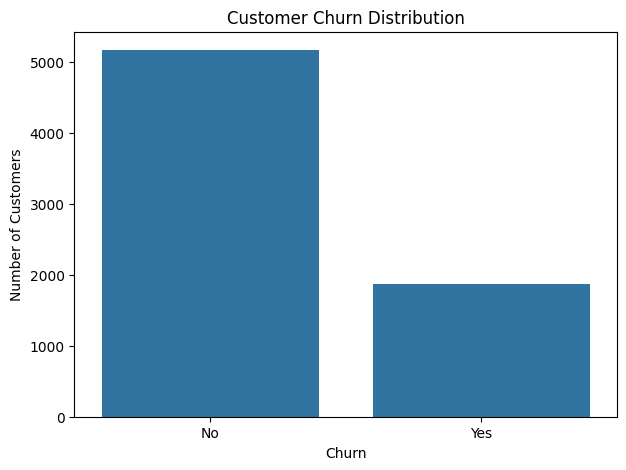

Churn Counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn Percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [21]:
# ============================================
# 12.1 Churn Distribution
# ============================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

# Numerical summary
churn_counts = df_clean["Churn"].value_counts()
churn_percentages = (
    df_clean["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Churn Counts:")
display(churn_counts)

print("\nChurn Percentages:")
display(churn_percentages)

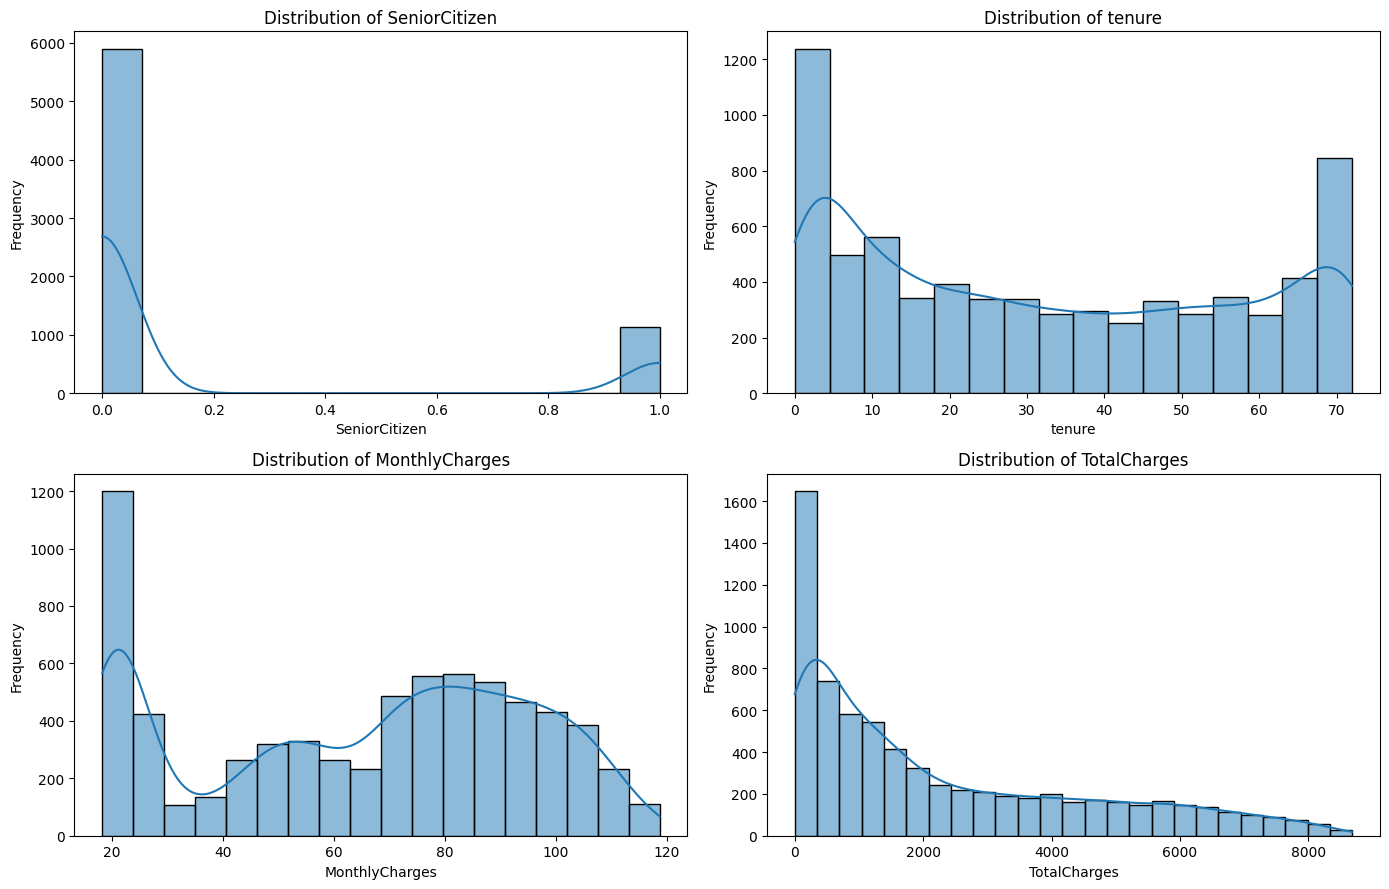

In [22]:
# ============================================
# 12.2 Numerical Feature Distributions
# ============================================

numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

for ax, feature in zip(axes.flatten(), numerical_features):
    sns.histplot(
        data=df_clean,
        x=feature,
        kde=True,
        ax=ax
    )
    
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

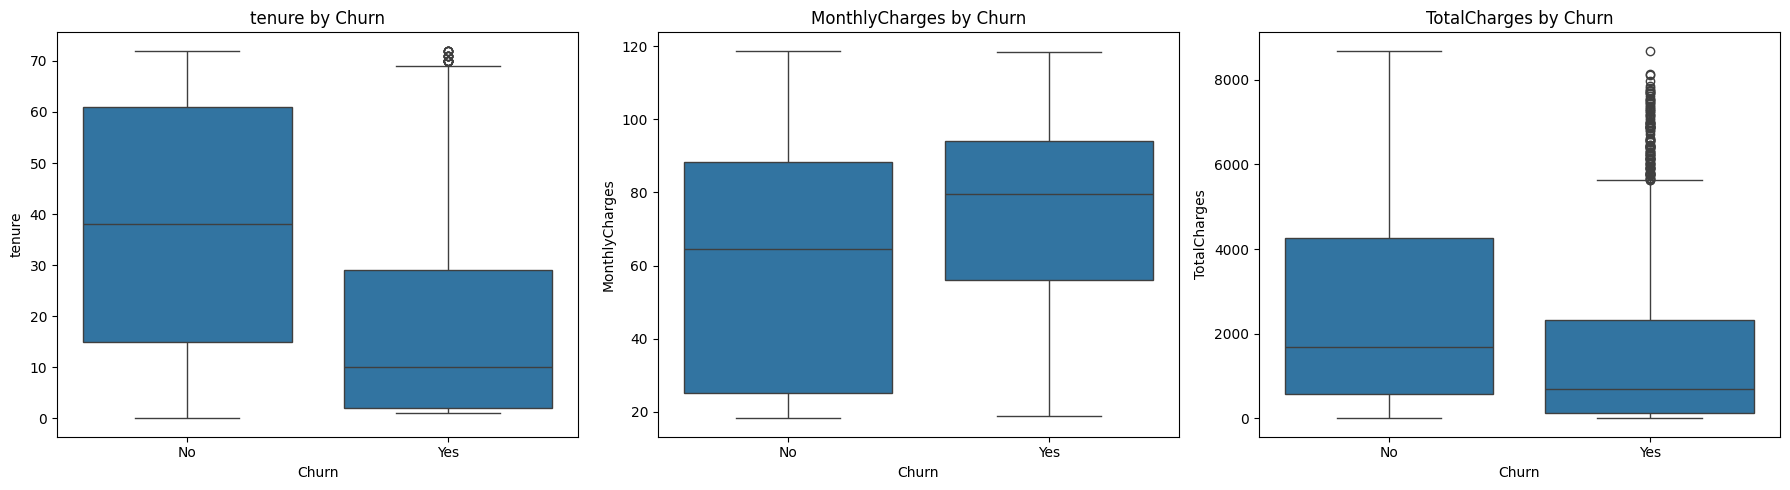

In [23]:
# ============================================
# 12.3 Churn vs Numerical Features
# ============================================

features_to_compare = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, feature in zip(axes, features_to_compare):
    sns.boxplot(
        data=df_clean,
        x="Churn",
        y=feature,
        ax=ax
    )
    
    ax.set_title(f"{feature} by Churn")
    ax.set_xlabel("Churn")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

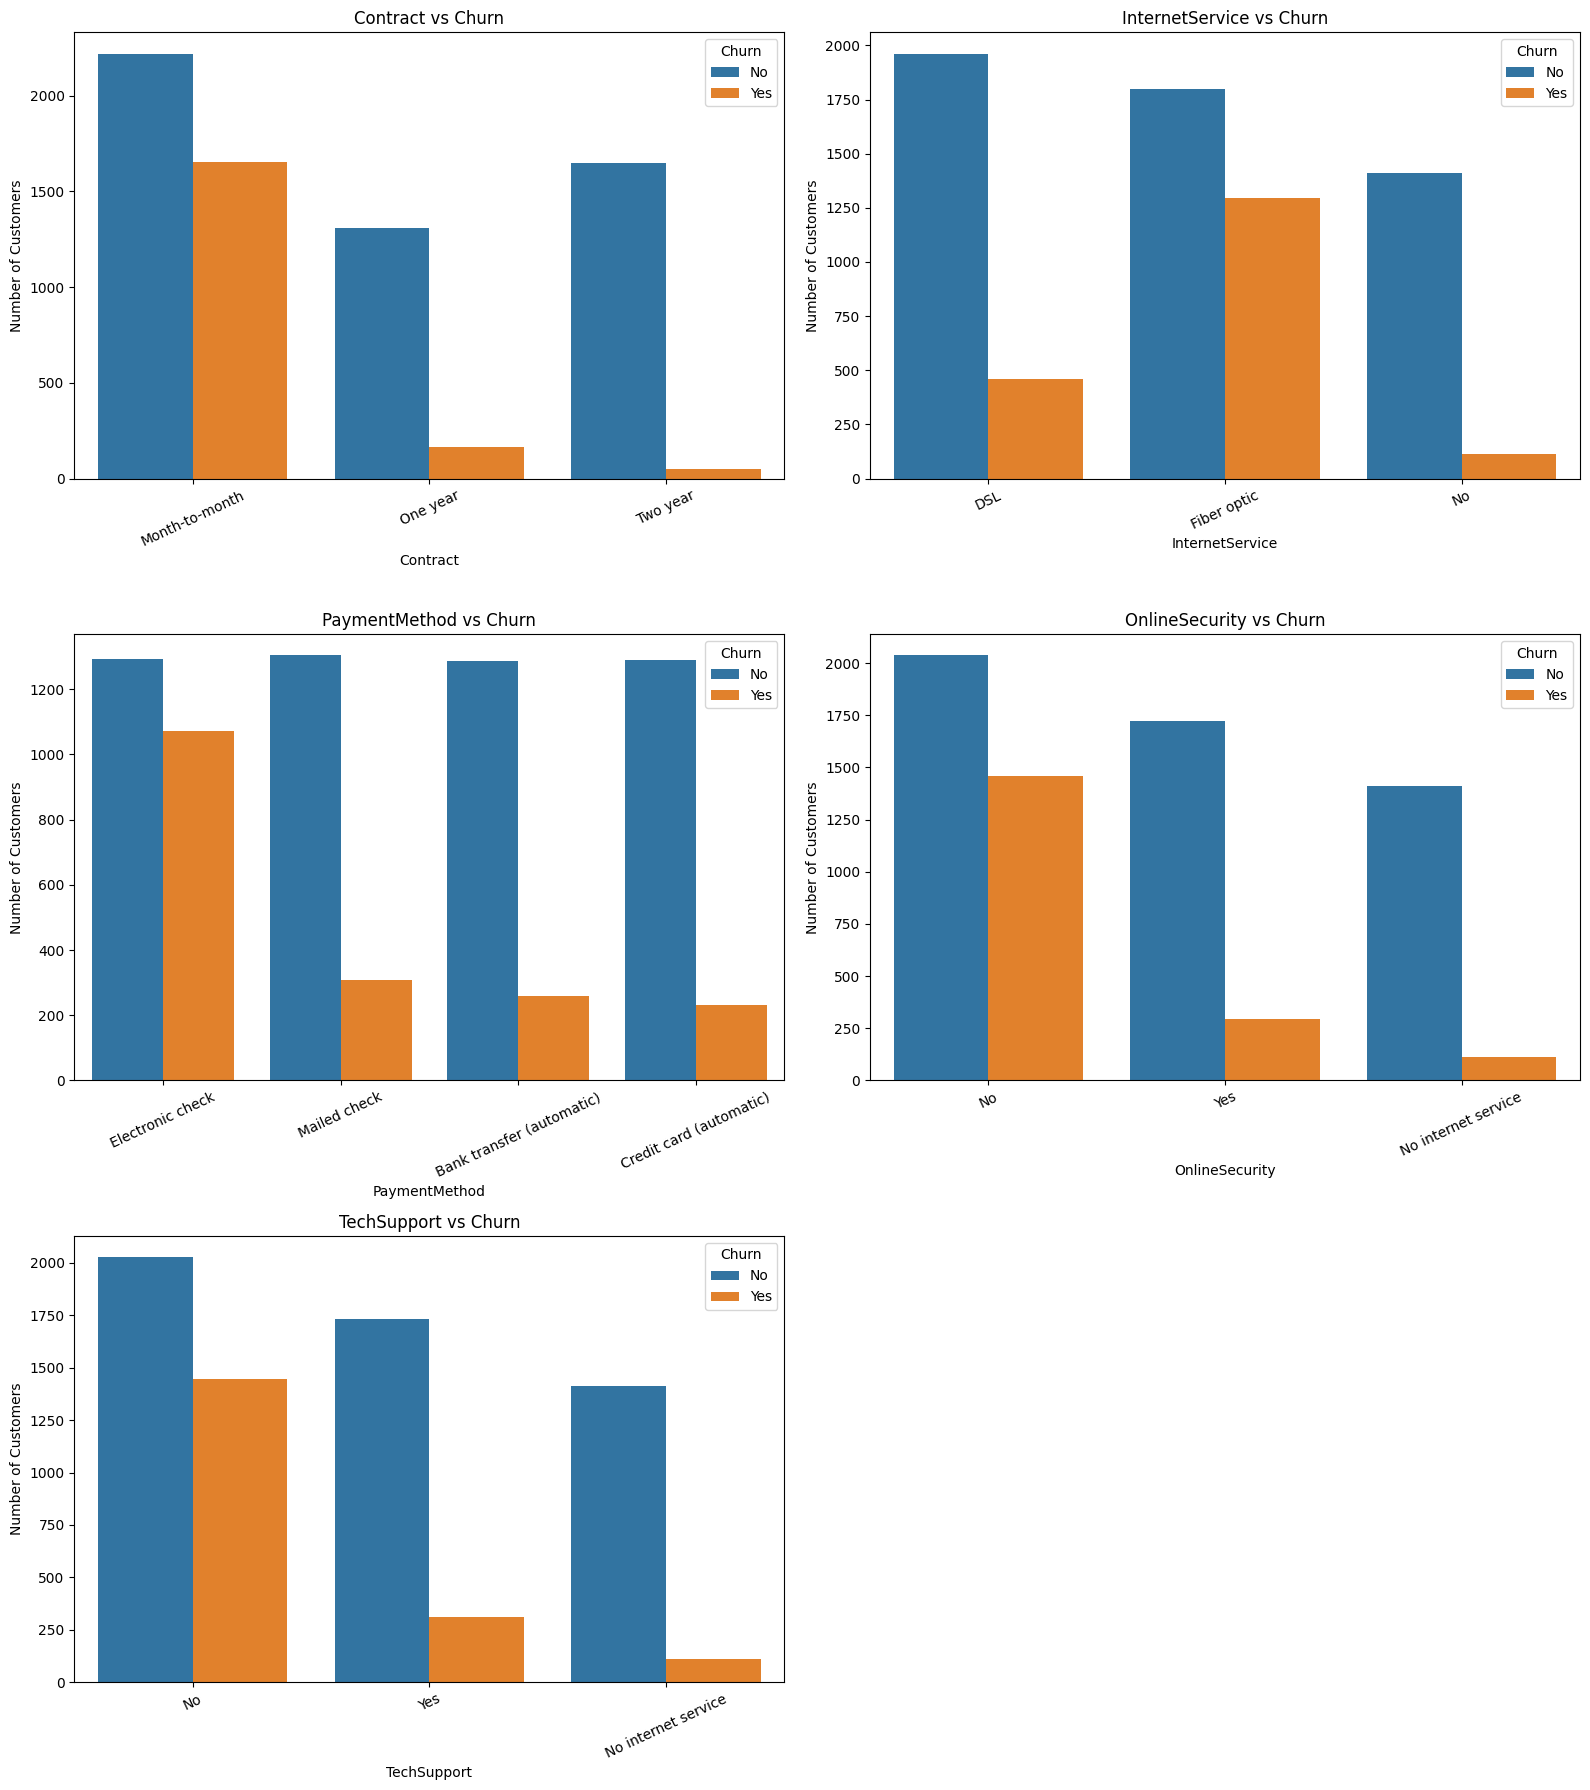

In [24]:
# ============================================
# 12.4 Categorical Features vs Churn
# ============================================

categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 18)
)

axes = axes.flatten()

for ax, feature in zip(axes, categorical_features):
    sns.countplot(
        data=df_clean,
        x=feature,
        hue="Churn",
        ax=ax
    )
    
    ax.set_title(f"{feature} vs Churn")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Customers")
    
    # Rotate labels where necessary
    ax.tick_params(axis="x", rotation=25)

# Hide unused subplot
axes[-1].axis("off")

plt.tight_layout()
plt.show()

## 12.5 Churn Rate by Categorical Features

Count plots show the number of customers in each category, but categories may contain different numbers of customers.

To make the comparison more meaningful, we calculate the percentage of customers who churn within each category.

This allows us to identify categorical groups with different observed churn rates.

In [25]:
# ============================================
# 12.5 Churn Rate by Categorical Features
# ============================================

categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling"
]

for feature in categorical_features:
    churn_rate = (
        pd.crosstab(
            df_clean[feature],
            df_clean["Churn"],
            normalize="index"
        )["Yes"]
        .mul(100)
        .sort_values(ascending=False)
    )

    print("\n" + "=" * 70)
    print(f"Churn Rate by {feature}")
    print("=" * 70)

    display(churn_rate.round(2).rename("Churn Rate (%)"))


Churn Rate by Contract


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn Rate (%), dtype: float64


Churn Rate by InternetService


InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn Rate (%), dtype: float64


Churn Rate by PaymentMethod


...

OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn Rate (%), dtype: float64


Churn Rate by TechSupport


TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn Rate (%), dtype: float64


Churn Rate by PaperlessBilling


PaperlessBilling
Yes    33.57
No     16.33
Name: Churn Rate (%), dtype: float64

In [26]:
# ============================================
# 12.6 Numerical Features by Churn
# ============================================

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

summary = (
    df_clean
    .groupby("Churn")[numerical_features]
    .agg(["mean", "median"])
    .round(2)
)

display(summary)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

## 13. Feature Engineering

Feature engineering is the process of preparing and transforming raw variables into representations that are suitable for machine learning.

For this project, the main feature-engineering decisions are:

- Remove `customerID` because it is an identifier rather than a meaningful predictive feature.
- Convert the binary target `Churn` into numerical labels.
- Separate numerical and categorical features.
- Preserve meaningful categorical information for later encoding.
- Apply scaling to numerical features where required by the selected algorithms.

We will avoid unnecessary transformations and allow the preprocessing pipeline to handle encoding and scaling consistently.

In [27]:
# ============================================
# 13.1 Define Features and Target
# ============================================

# Work from the cleaned dataset
model_df = df_clean.copy()

# Remove customer identifier
model_df = model_df.drop(columns=["customerID"])

# Convert target into binary values
model_df["Churn"] = model_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Separate features and target
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

print("\nTarget percentages:")
display((y.value_counts(normalize=True) * 100).round(2))

Feature matrix shape: (7043, 19)
Target shape: (7043,)

Target distribution:


Churn
0    5174
1    1869
Name: count, dtype: int64


Target percentages:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

In [28]:
# ============================================
# 13.2 Identify Feature Types
# ============================================

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


## 14. Train/Test Split and Preprocessing

Before preprocessing the features, the dataset is divided into training and testing sets.

The training set will be used to learn the preprocessing parameters and train the machine learning models.

The test set will remain unseen during training and will only be used for final model evaluation.

A stratified split is used so that the proportion of churned and non-churned customers remains approximately consistent in both sets.

In [29]:
# ============================================
# 14.1 Train/Test Split
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
display(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

print("\nTesting target distribution:")
display(
    (y_test.value_counts(normalize=True) * 100).round(2)
)

Training set:
X_train: (5634, 19)
y_train: (5634,)

Testing set:
X_test: (1409, 19)
y_test: (1409,)

Training target distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


Testing target distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

## 14.2 Preprocessing Pipeline

The dataset contains both numerical and categorical features, so different preprocessing operations are required.

### Numerical features

Numerical features will be standardized using `StandardScaler`.

### Categorical features

Categorical features will be converted into numerical representations using `OneHotEncoder`.

A `ColumnTransformer` will apply the appropriate transformation to each feature type.

This preprocessing will later be combined with machine learning models using Scikit-learn pipelines. This helps prevent data leakage and ensures that the exact same transformations can be applied when making predictions through the FastAPI service.

In [30]:
# ============================================
# 14.2 Preprocessing Pipeline
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")
print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Preprocessing pipeline created successfully.

Numerical features: 4
Categorical features: 15


In [31]:
# ============================================
# 14.3 Verify Preprocessing
# ============================================

print("Preprocessor configuration:")
print(preprocessor)

print("\nNumerical columns:")
print(numerical_features)

print("\nCategorical columns:")
print(categorical_features)

Preprocessor configuration:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup

## 15. Class Imbalance Analysis

The target variable contains two classes:

- 0 = No Churn
- 1 = Churn

Approximately 73.46% of customers did not churn, while 26.54% churned.

This indicates class imbalance.

Because predicting churn is important for this project, accuracy alone is not sufficient for evaluating the models. Precision, recall, F1-score, confusion matrix, and ROC-AUC will also be considered.

We will initially train the models using the original class distribution and evaluate their performance. If necessary, class-weighting or another imbalance-handling strategy can be investigated based on the results.

,Count,Percentage
No Churn (0),5174,73.46
Churn (1),1869,26.54


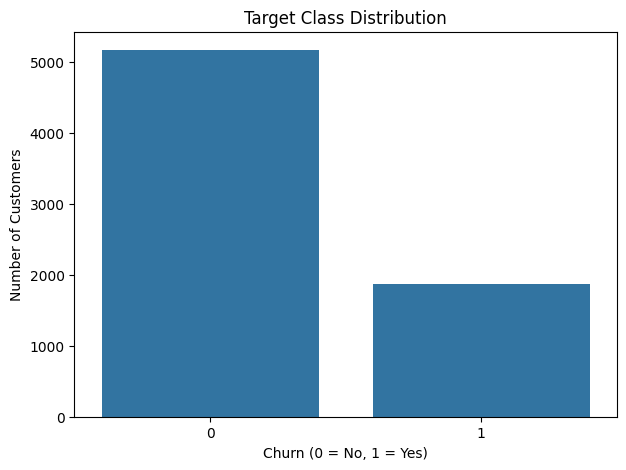

In [32]:
# ============================================
# 15.1 Class Distribution
# ============================================

class_counts = pd.DataFrame({
    "Count": y.value_counts(),
    "Percentage": (
        y.value_counts(normalize=True) * 100
    ).round(2)
})

class_counts.index = [
    "No Churn (0)" if i == 0 else "Churn (1)"
    for i in class_counts.index
]

display(class_counts)

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y
)

plt.title("Target Class Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

## 16. Model Training

Five supervised classification algorithms will be trained and compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost
5. Support Vector Machine (SVM)

Each model will be combined with the preprocessing pipeline so that numerical scaling and categorical encoding are learned only from the training data.

In [33]:
# ============================================
# 16.1 Import Machine Learning Models
# ============================================

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

print("All models imported successfully.")

All models imported successfully.


In [34]:
# ============================================
# 16.2 Create Model Pipelines
# ============================================

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            random_state=42,
            eval_metric="logloss"
        ))
    ]),

    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

print(f"Created {len(models)} model pipelines:\n")

for name in models:
    print("-", name)

Created 5 model pipelines:

- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- SVM


In [35]:
# ============================================
# 16.3 Train All Models
# ============================================

trained_models = {}

print("=" * 70)
print("MODEL TRAINING")
print("=" * 70)

for name, pipeline in models.items():
    print(f"\nTraining {name}...")
    
    pipeline.fit(X_train, y_train)
    
    trained_models[name] = pipeline
    
    print(f"{name} trained successfully.")

print("\n" + "=" * 70)
print("ALL MODELS TRAINED SUCCESSFULLY")
print("=" * 70)

MODEL TRAINING

Training Logistic Regression...
Logistic Regression trained successfully.

Training Decision Tree...
Decision Tree trained successfully.

Training Random Forest...
Random Forest trained successfully.

Training XGBoost...
XGBoost trained successfully.

Training SVM...
SVM trained successfully.

ALL MODELS TRAINED SUCCESSFULLY


## 17. Model Evaluation

The trained models will be evaluated on the unseen test dataset.

The following metrics will be used:

- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Among customers predicted as churners, the proportion who actually churned.
- **Recall:** Among customers who actually churned, the proportion correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Measures the model's ability to distinguish between the two classes across classification thresholds.

Because the dataset is imbalanced, accuracy will not be used as the only model-selection criterion.

In [36]:
# ============================================
# 17.1 Evaluate All Models
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in trained_models.items():
    
    # Predictions
    y_pred = model.predict(X_test)
    
    # Probability of positive class
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

# Round values for readability
results_df[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
] = results_df[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].round(4)

display(
    results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,XGBoost,0.8006,0.6535,0.5294,0.5849,0.8439
2,SVM,0.7913,0.6418,0.4840,0.5518,0.7902
3,Random Forest,0.7835,0.6186,0.4813,0.5414,0.8206
4,Decision Tree,0.7211,0.4755,0.4920,0.4836,0.6477


## 18. Confusion Matrix Analysis

A confusion matrix provides a detailed view of classification errors.

For this project:

- True Negative (TN): Correctly predicted no churn
- False Positive (FP): Predicted churn when the customer did not churn
- False Negative (FN): Predicted no churn when the customer actually churned
- True Positive (TP): Correctly predicted churn

False negatives are particularly important to examine because they represent customers who actually churned but were not identified by the model.

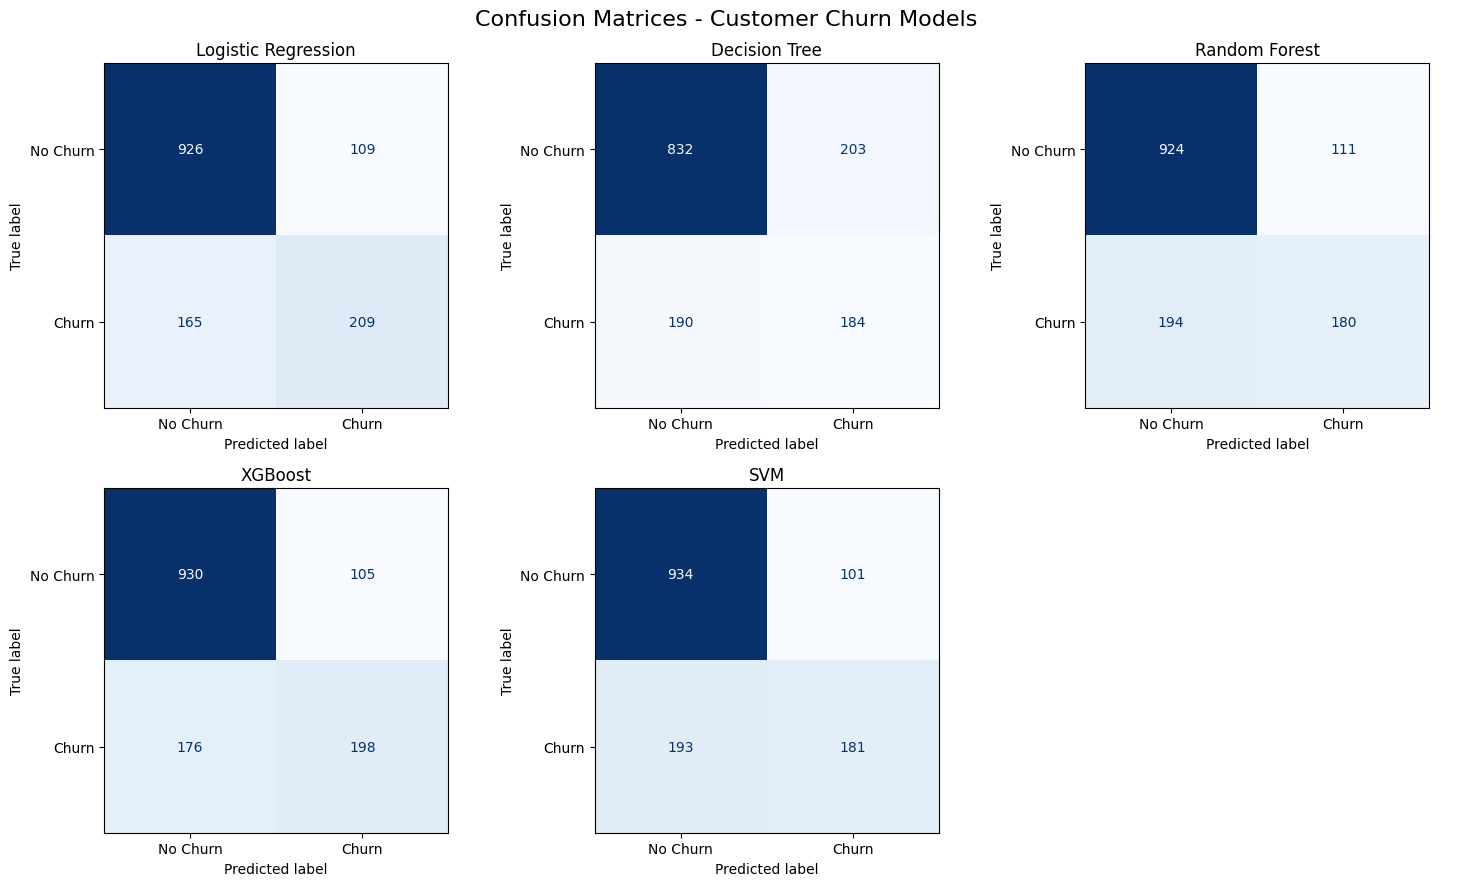

In [37]:
# ============================================
# 18.1 Confusion Matrices for All Models
# ============================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    disp.plot(
        ax=axes[i],
        cmap="Blues",
        colorbar=False
    )

    axes[i].set_title(name)

# Hide unused subplot
axes[-1].axis("off")

plt.suptitle(
    "Confusion Matrices - Customer Churn Models",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [38]:
# ============================================
# 18.2 Exact Confusion Matrix Values
# ============================================

confusion_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    confusion_results.append({
        "Model": name,
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp
    })

confusion_df = pd.DataFrame(confusion_results)

display(confusion_df)

,Model,True Negative,False Positive,False Negative,True Positive
0,Logistic Regression,926,109,165,209
1,Decision Tree,832,203,190,184
2,Random Forest,924,111,194,180
3,XGBoost,930,105,176,198
4,SVM,934,101,193,181


## 19. ROC-AUC Comparison

The ROC curve shows the relationship between the true positive rate and false positive rate at different classification thresholds.

ROC-AUC summarizes this behavior into a single value:

- 0.5 ≈ random classification
- 1.0 = perfect discrimination

ROC-AUC will be considered alongside precision, recall, F1-score, and the confusion matrix rather than being used alone.

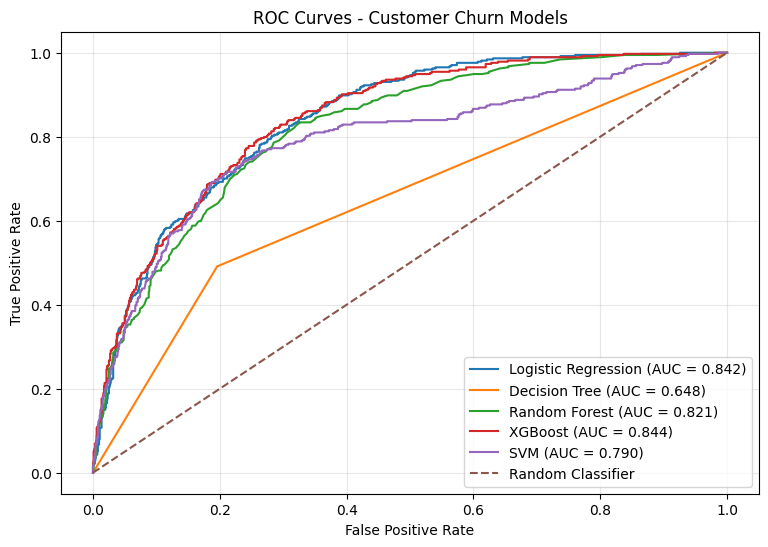

In [39]:
# ============================================
# 19.1 ROC Curves
# ============================================

from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 6))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Customer Churn Models")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 20. Cross-Validation

A single train-test split can sometimes give an unstable estimate of model performance.

To obtain a more reliable evaluation, Stratified K-Fold Cross-Validation is applied to the training data.

Stratification preserves the proportion of churn and non-churn customers in each fold.

The test set remains untouched and is not used during cross-validation or hyperparameter tuning.

In [40]:
# ============================================
# 20.1 Stratified Cross-Validation
# ============================================

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in trained_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.8021,0.6529,0.5431,0.5923,0.8462
1,Decision Tree,0.7267,0.4855,0.4970,0.4909,0.6534
2,Random Forest,0.7838,0.6222,0.4736,0.5374,0.8199
3,XGBoost,0.8044,0.6660,0.5291,0.5894,0.8470
4,SVM,0.8035,0.6772,0.4977,0.5735,0.7998


## 21. Hyperparameter Tuning

Hyperparameter tuning is performed to identify model configurations that provide better generalization.

Only the training data is used during tuning. The test set remains completely untouched until the final evaluation.

Logistic Regression and XGBoost are selected for tuning based on their cross-validation performance.

In [43]:
# ============================================
# 21.1 Logistic Regression Hyperparameter Tuning
# ============================================

from sklearn.model_selection import GridSearchCV

logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": [None, "balanced"]
}

logistic_grid = GridSearchCV(
    estimator=trained_models["Logistic Regression"],
    param_grid=logistic_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("\nBest Cross-Validation F1:")
print(round(logistic_grid.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Logistic Regression Parameters:
{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}

Best Cross-Validation F1:
0.6295


In [45]:
# ============================================
# 21.2 XGBoost Hyperparameter Tuning
# ============================================

xgb_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=trained_models["XGBoost"],
    param_grid=xgb_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_grid.best_params_)

print("\nBest Cross-Validation F1:")
print(round(xgb_grid.best_score_, 4))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best XGBoost Parameters:
{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}

Best Cross-Validation F1:
0.5927


## 22. Final Test Evaluation

After hyperparameter tuning using cross-validation on the training data, the tuned Logistic Regression and XGBoost models are evaluated on the previously untouched test set.

The final evaluation includes accuracy, precision, recall, F1-score, and ROC-AUC.

In [46]:
# ============================================
# 22.1 Final Test Evaluation
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

final_models = {
    "Tuned Logistic Regression": logistic_grid.best_estimator_,
    "Tuned XGBoost": xgb_grid.best_estimator_
}

final_results = []

for name, model in final_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

final_df = pd.DataFrame(final_results)

display(final_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Logistic Regression,0.741,0.5078,0.7861,0.617,0.8410
1,Tuned XGBoost,0.802,0.6610,0.5214,0.583,0.8456


## 23. Final Confusion Matrices

Confusion matrices are used to analyze the final classification behavior of the tuned Logistic Regression and XGBoost models.

They show the number of:
- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)
- True Positives (TP)

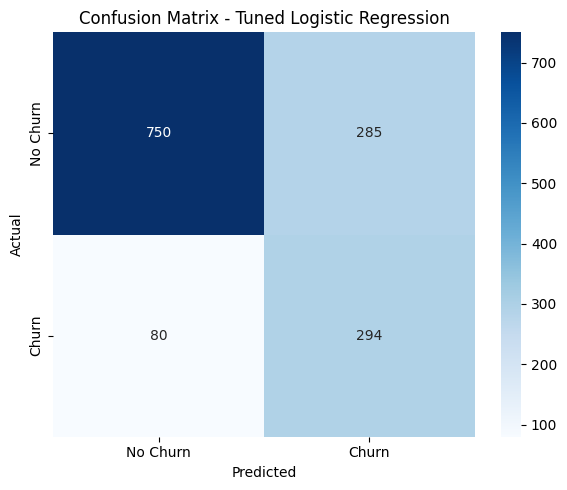

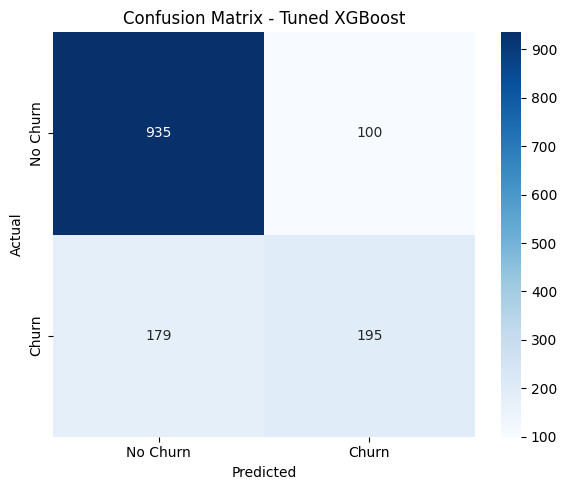

In [47]:
# ============================================
# 23.1 Final Confusion Matrices
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in final_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

## 24. Final Model Comparison

The final comparison evaluates the tuned Logistic Regression and XGBoost models using their performance on the previously unseen test set.

The comparison considers accuracy, precision, recall, F1-score, and ROC-AUC. Confusion matrices are also considered to understand the practical trade-off between detecting churners and generating false positives.

In [50]:
# ============================================
# 24.1 Final Model Comparison
# ============================================

comparison_df = pd.DataFrame([
    {
        "Model": "Tuned Logistic Regression",
        "Accuracy": 0.7410,
        "Precision": 0.5078,
        "Recall": 0.7861,
        "F1-Score": 0.6170,
        "ROC-AUC": 0.8410
    },
    {
        "Model": "Tuned XGBoost",
        "Accuracy": 0.8020,
        "Precision": 0.6610,
        "Recall": 0.5214,
        "F1-Score": 0.5830,
        "ROC-AUC": 0.8456
    }
])

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Logistic Regression,0.741,0.5078,0.7861,0.617,0.8410
1,Tuned XGBoost,0.802,0.6610,0.5214,0.583,0.8456


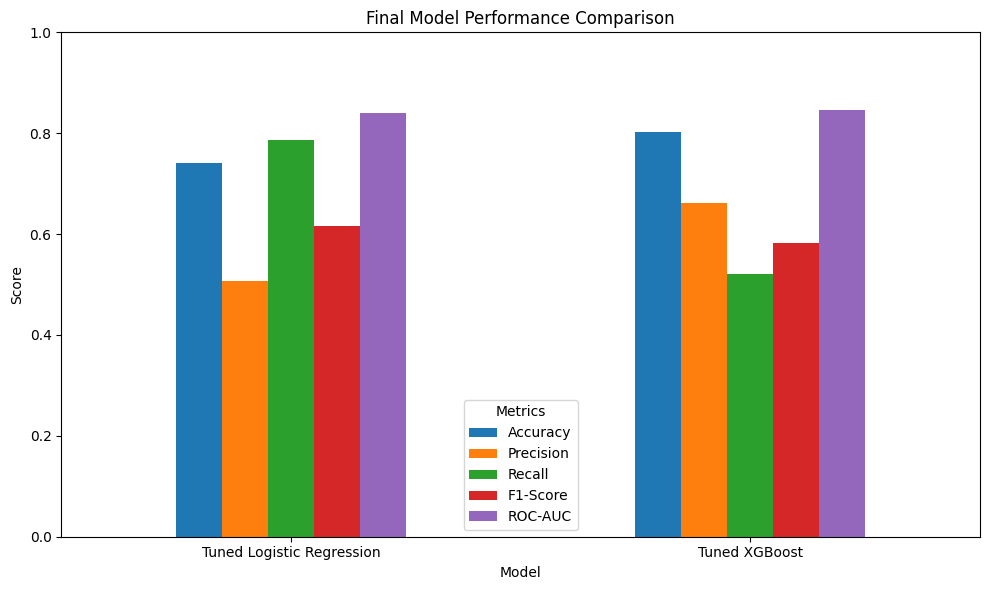

In [51]:
# ============================================
# 24.2 Model Performance Visualization
# ============================================

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

comparison_plot = comparison_df.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Final Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

## 25. Model Interpretation

Model interpretation is used to understand which customer characteristics have the strongest influence on churn predictions.

For Logistic Regression, model coefficients are examined after preprocessing. Positive coefficients indicate features associated with higher churn probability, while negative coefficients indicate features associated with lower churn probability.

In [52]:
# ============================================
# 25.1 Logistic Regression Feature Importance
# ============================================

import pandas as pd
import numpy as np

log_model = logistic_grid.best_estimator_

# Get preprocessing and model components
preprocessor = log_model.named_steps["preprocessor"]
classifier = log_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = classifier.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Coefficient": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(feature_importance.head(20))

,Feature,Coefficient,Absolute_Coefficient
1,num__tenure,-0.980335,0.980335
38,cat__Contract_Two year,-0.692290,0.692290
36,cat__Contract_Month-to-month,0.629538,0.629538
15,cat__InternetService_DSL,-0.357999,0.357999
16,cat__InternetService_Fiber optic,0.331094,0.331094
3,num__TotalCharges,0.293099,0.293099
43,cat__PaymentMethod_Electronic check,0.247579,0.247579
39,cat__PaperlessBilling_No,-0.241449,0.241449
20,cat__OnlineSecurity_Yes,-0.231143,0.231143
12,cat__MultipleLines_No,-0.215146,0.215146


## 26. Logistic Regression Feature Importance

The absolute magnitude of Logistic Regression coefficients is used to identify the features that have the strongest influence on the model's predictions.

Positive and negative coefficients are preserved to distinguish features associated with higher or lower predicted churn.

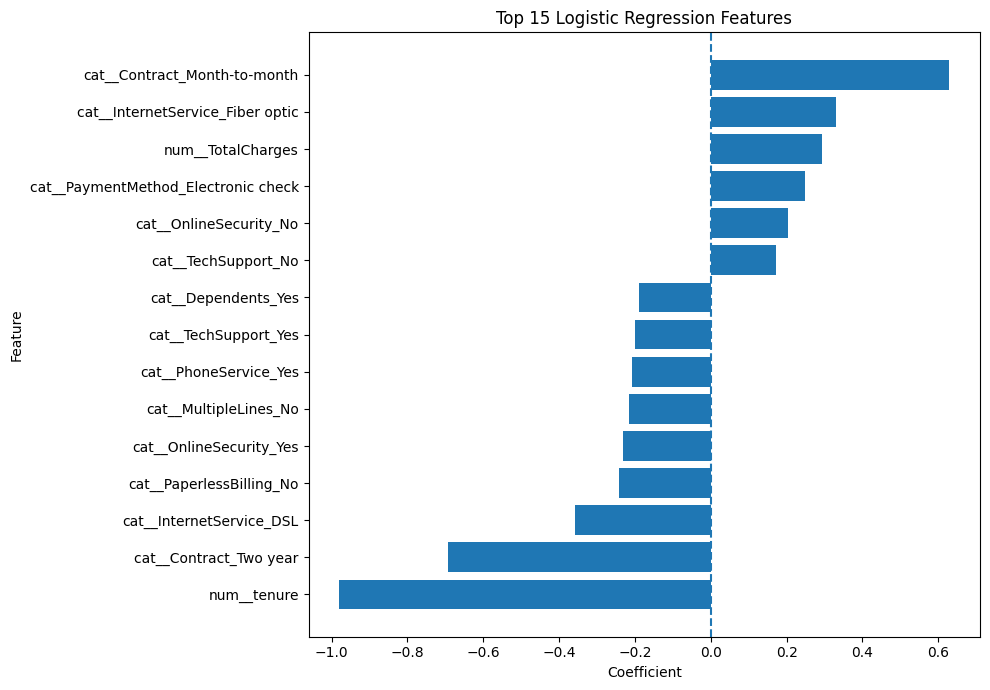

In [53]:
# ============================================
# 26.1 Top 15 Logistic Regression Features
# ============================================

top_features = feature_importance.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.title("Top 15 Logistic Regression Features")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [54]:
# ============================================
# 27.1 Save Final Logistic Regression Model
# ============================================

import joblib
import os

os.makedirs("saved_model", exist_ok=True)

final_model = logistic_grid.best_estimator_

model_path = "saved_model/churn_logistic_regression.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: saved_model/churn_logistic_regression.pkl


In [55]:
# ============================================
# 27.2 Save XGBoost Model
# ============================================

xgb_model_path = "saved_model/churn_xgboost.pkl"

joblib.dump(
    xgb_grid.best_estimator_,
    xgb_model_path
)

print("XGBoost model saved successfully!")
print("Location:", xgb_model_path)

XGBoost model saved successfully!
Location: saved_model/churn_xgboost.pkl


In [59]:
import os
print(os.getcwd())

C:\Users\PMLS\Customer-Churn-Prediction\notebooks
